# APRENDIZAJE AUTOMÁTICO Y ANÁLISIS VISUAL DE DATOS
Jaime Rodrigo Roldán Corcelles

## Ejercicio práctico: Calidad y preprocesado de datos

### EJERCICIOS BÁSICOS
1) (3 ptos) Considere el conjunto de muestras crx.csv disponible en el Campus Virtual y realice las siguientes tareas. Ayúdese también si lo desea de la siguiente información:<br>

Rango de valores de los rasgos por orden de aparición y clase deseada:<br>
A1: b, a.<br>
A2: vble. numérica<br>
A3: vble. numérica<br>
A4: u, y, l, t.<br>
A5: g, p, gg.<br>
A6: c, d, cc, i, j, k, m, r, q, w, x, e, aa, ff.<br>
A7: v, h, bb, j, n, z, dd, ff, o.<br>
A8: vble. numérica<br>
A9: t, f.<br>
A10: t, f.<br>
A11: vble. numérica<br>
A12: t, f.<br>
A13: g, p, s.<br>
A14: vble. numérica<br>
A15: vble. numérica<br>
A16: +,- (clase deseada)<br>

Los valores desconocidos se han marcado con el carácter ?<br>
Cantidad de valores desconocidos por atributo:<br>
A1: 12<br>
A2: 12<br>
A4: 6<br>
A5: 6<br>
A6: 9<br>
A7: 9<br>
A14: 13<br>

a) Cargue las muestras en un DataFrame y elimine las muestras con atributos desconocidos.

In [62]:
import pandas as pd
import numpy as np

# Definimos los nombres de las columnas
columnas = [f'A{i}' for i in range(1, 17)]

# Cargamos el csv
df = pd.read_csv('data/crx.csv', header=None, names=columnas)

# Reemplazamos los '?' por NaN y eliminamos las filas incompletas
df = df.replace('?', np.nan)
df = df.dropna(axis=0)

print(f"Muestras tras eliminar valores desconocidos: {df.shape[0]}")

Muestras tras eliminar valores desconocidos: 653


b) Observe los valores de las muestras del DataFrame y muestre el tipo de datos de los atributos del DataFrame. Nota: use el método dtypes de DataFrame. ¿Son coherentes los tipos de datos de todos los atributos con los valores que contienen? ¿Por qué cree que ha sucedido esto?

In [63]:
print(df.dtypes)

A1         str
A2         str
A3     float64
A4         str
A5         str
A6         str
A7         str
A8     float64
A9         str
A10        str
A11      int64
A12        str
A13        str
A14        str
A15      int64
A16        str
dtype: object


No son coherentes. Al cargar el archivo, Pandas encontró el carácter '?' en variables que debían ser numéricas (A2 y A14). Para no perder datos, asignó automáticamente el tipo object a toda la columna.

c) Asigne el tipo de dato adecuado a las columnas que no estén correctas. Nota: ayúdese de la función to_numeric de Pandas.

In [64]:
# Cambiamos A2 y A14 a numérico
df['A2'] = pd.to_numeric(df['A2'])
df['A14'] = pd.to_numeric(df['A14'])

print(df.dtypes)

A1         str
A2     float64
A3     float64
A4         str
A5         str
A6         str
A7         str
A8     float64
A9         str
A10        str
A11      int64
A12        str
A13        str
A14      int64
A15      int64
A16        str
dtype: object


d) Preprocese los datos para que sea posible entrenar con ellos un modelo predictivo. Explique lo que realiza y por qué.

In [65]:
from sklearn.preprocessing import LabelEncoder

# Separar rasgos (X) y la variable objetivo (y)
X = df.drop('A16', axis=1)
y = df['A16']

le = LabelEncoder()
y = le.fit_transform(y)

X = pd.get_dummies(X, drop_first=True)

Los algoritmos predictivos solo entienden números. Por ello:

Label Encoding: Transforma la variable objetivo ('+', '-') a binario (1, 0).

One-Hot Encoding: Convierte las categorías en columnas de 0s y 1s. Usamos drop_first=True para eliminar la primera columna generada y evitar redundancia de información.

e) Divida el conjunto de datos en un 75% para entrenamiento y un 25% para test.

In [66]:
from sklearn.model_selection import train_test_split

X_ent, X_test, y_ent, y_test = train_test_split(
    X, y, 
    test_size=0.25,      # 25% para test
    random_state=10, 
    stratify=y          
)

f) Realice un escalado estándar de las muestras.

In [67]:
from sklearn.preprocessing import StandardScaler

escaladorEstandar = StandardScaler()

# Ajustamos y transformamos el conjunto de entrenamiento
X_ent_std = escaladorEstandar.fit_transform(X_ent)

# Solo transformamos el conjunto de test (no se hace fit sobre test)
X_test_std = escaladorEstandar.transform(X_test)

g) Muestre dos gráficas comparando la distribución de muestras en el plano antes y después de escalar, elija los dos atributos numéricos que quiera. Recuerde que debe usar la misma escala en ambos ejes para que se observen las diferencias entre atributos. Comente si existen o no diferencias al realizar el escalado.

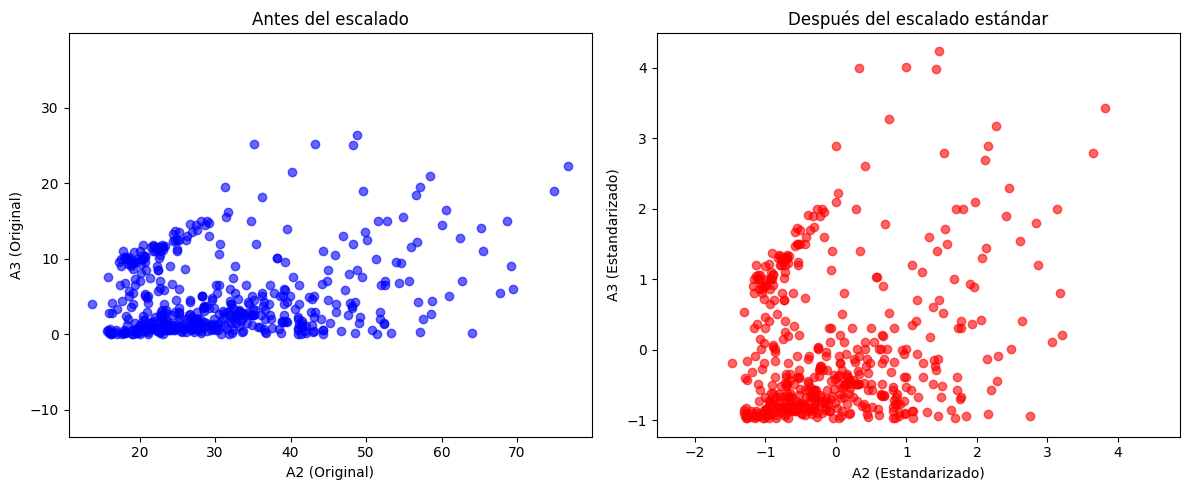

In [68]:

import matplotlib.pyplot as plt

# Buscamos los índices de las columnas numéricas que queremos mostrar (A2 y A3)
idx_a2 = X.columns.get_loc('A2')
idx_a3 = X.columns.get_loc('A3')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Gráfica 1: Antes del escalado
ax[0].scatter(X_ent.iloc[:, idx_a2], X_ent.iloc[:, idx_a3], alpha=0.6, c='blue')
ax[0].set_xlabel('A2 (Original)')
ax[0].set_ylabel('A3 (Original)')
ax[0].set_title('Antes del escalado')
ax[0].axis('equal')

# Gráfica 2: Después del escalado
ax[1].scatter(X_ent_std[:, idx_a2], X_ent_std[:, idx_a3], alpha=0.6, c='red')
ax[1].set_xlabel('A2 (Estandarizado)')
ax[1].set_ylabel('A3 (Estandarizado)')
ax[1].set_title('Después del escalado estándar')
ax[1].axis('equal')

plt.tight_layout()
plt.show()

Sí, existen claras diferencias. En la gráfica original, la variable con valores más altos domina el espacio. Al aplicar el escalado estándar (media 0, varianza 1), ambas variables pasan a tener la misma escala, logrando una dispersión homogénea y comparable.

h) Entrene dos modelos KNN, uno entrenado con las muestras originales y otro con las muestras escaladas. Compare y comente el rendimiento obtenido en test en cada caso.

In [69]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Modelo KNN con los datos originales 
knn_orig = KNeighborsClassifier()
knn_orig.fit(X_ent, y_ent)

# Realizamos las predicciones sobre el conjunto de test original y medimos su acierto
y_pred_orig = knn_orig.predict(X_test)
rendimiento_orig = accuracy_score(y_test, y_pred_orig)

# 2. Modelo KNN con los datos escalados
knn_std = KNeighborsClassifier()
knn_std.fit(X_ent_std, y_ent)

# Realizamos las predicciones sobre el conjunto de test escalado y medimos su acierto
y_pred_std = knn_std.predict(X_test_std)
rendimiento_std = accuracy_score(y_test, y_pred_std)

print(f"Rendimiento en test (Datos Originales): {rendimiento_orig * 100:.2f} %")
print(f"Rendimiento en test (Datos Escalados): {rendimiento_std * 100:.2f} %")

Rendimiento en test (Datos Originales): 64.63 %
Rendimiento en test (Datos Escalados): 79.88 %


El modelo escalado es mucho mejor (79.88 % frente al 64.63 % del original). KNN clasifica midiendo distancias; si no escalamos, las variables con números más grandes dominan completamente el cálculo. Estandarizar iguala el "peso" de todos los atributos, mejorando notablemente la exactitud del modelo.

2) (3 ptos) Considere nuevamente el conjunto de muestras crx.csv disponible en el Campus Virtual, pero en esta ocasión realice las siguientes tareas:

a) Rellene los datos incompletos empleando la media para los atributos numéricos y la moda para los no numéricos. Nota: puede utilizar los métodos loc o bien iloc de DataFrame para referenciar y rellenar aquellos atributos incompletos, dejando el resto de atributos inalterados.

In [70]:
import pandas as pd
import numpy as np

# Carga inicial y limpieza del símbolo '?'
columnas = [f'A{i}' for i in range(1, 17)]
df = pd.read_csv('data/crx.csv', header=None, names=columnas)
df = df.replace('?', np.nan)

# Corrección de tipos
df['A2'] = pd.to_numeric(df['A2'])
df['A14'] = pd.to_numeric(df['A14'])

# Separamos las columnas por numéricas y categóricas (texto)
cols_num = df.select_dtypes(include=[np.number]).columns
cols_cat = df.select_dtypes(include=['object']).columns

# Rellenamos numéricas con la Media
for col in cols_num:
    df[col] = df[col].fillna(df[col].mean())

# Rellenamos categóricas con la Moda
for col in cols_cat:
    df[col] = df[col].fillna(df[col].mode().iloc[0])

C:\Users\rodri\AppData\Local\Temp\ipykernel_18496\1888632577.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = df.select_dtypes(include=['object']).columns


b) Asigne el tipo de dato adecuado a las columnas que no estén correctas. Preprocese los datos para que sea posible entrenar con ellos un modelo predictivo. Divida el conjunto de datos en un 75% para entrenamiento y un 25% para test. Realice un escalado estándar de las muestras.

In [71]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# 1. Preprocesado
X = df.drop('A16', axis=1)
y = df['A16']

y = LabelEncoder().fit_transform(y) 
X = pd.get_dummies(X, drop_first=True) 

# 2. División (75% Entrenamiento y 25% Test)
X_ent, X_test, y_ent, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10, stratify=y
)

# 3. Escalado Estándar
escalador = StandardScaler()
X_ent_std = escalador.fit_transform(X_ent)
X_test_std = escalador.transform(X_test)

c) Aplique una selección secuencial de rasgos (SBS) utilizando neuronas logísticas como estimador. Dibuje una gráfica de exactitud en test en función de la cantidad de rasgos seleccionados. ¿Qué cantidad de rasgos es la óptima?

In [72]:
from sklearn.base import clone
from itertools import combinations
import numpy as np
from sklearn.metrics import accuracy_score

class SBS():
    def __init__(self, estimador, l_rasgos_obj, scoring=accuracy_score):
        self.scoring = scoring
        self.estimador = clone(estimador)
        self.l_rasgos_obj = l_rasgos_obj

    def ajustar(self, X_ent, X_test, y_ent, y_test):
        # Contador de cantidad de rasgos actuales:
        k_rasgos_act = X_ent.shape[1]
        # Vector con los índices de los rasgos actuales:
        self.indices_ = tuple(range(k_rasgos_act))
        # Lista con los subconjuntos de rasgos elegidos:
        self.subconjuntos_ = [self.indices_]
        # Cálculo del rendimiento con el conjunto inicial:
        rendimiento = self._calcular_rendimiento(X_ent, y_ent, X_test, y_test, self.indices_)
        self.rendimientos_ = [rendimiento]
        
        while k_rasgos_act > self.l_rasgos_obj:
            lista_rend_p = []
            subconjuntos_p = []

            # Probamos todas las combinaciones con 1 rasgo menos
            for p in combinations(self.indices_, r=k_rasgos_act - 1):
                rendimiento_p = self._calcular_rendimiento(X_ent, y_ent, X_test, y_test, p)
                lista_rend_p.append(rendimiento_p)
                subconjuntos_p.append(p)

            # Determinarmos cuál ha sido el mejor subconjunto
            mejor_p = np.argmax(lista_rend_p)

            # Anotamos como mejor para esta cantidad de rasgos a mejor_p
            self.indices_ = subconjuntos_p[mejor_p]
            self.subconjuntos_.append(self.indices_)
            self.rendimientos_.append(lista_rend_p[mejor_p])
            k_rasgos_act -= 1

        return self

    def _calcular_rendimiento(self, X_ent, y_train, X_test, y_test, indices):
        self.estimador.fit(X_ent[:, indices], y_train)
        y_pred = self.estimador.predict(X_test[:, indices])
        rendimiento = self.scoring(y_test, y_pred)
        return rendimiento

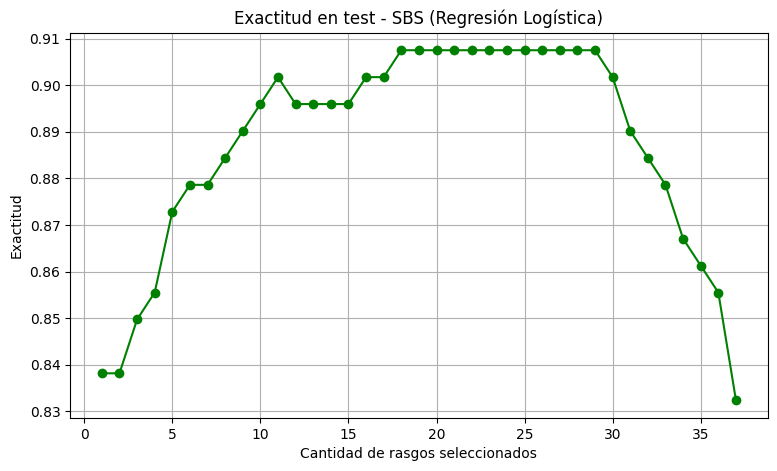

La cantidad óptima es 29 rasgos (Exactitud: 0.9075)


In [73]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

# Aplicar SBS con Regresión Logística
lr = LogisticRegression(random_state=1, max_iter=1000)
sbs = SBS(lr, l_rasgos_obj=1)
sbs.ajustar(X_ent_std, X_test_std, y_ent, y_test)

# Gráfica
cantidadRasgos = [len(subconj) for subconj in sbs.subconjuntos_]

plt.figure(figsize=(9, 5))
plt.plot(cantidadRasgos, sbs.rendimientos_, marker='o', color='green')
plt.title('Exactitud en test - SBS (Regresión Logística)')
plt.ylabel('Exactitud')
plt.xlabel('Cantidad de rasgos seleccionados')
plt.grid(True)
plt.show()

# Imprimir la cantidad óptima programáticamente
opt_idx = np.argmax(sbs.rendimientos_)
print(f"La cantidad óptima es {cantidadRasgos[opt_idx]} rasgos (Exactitud: {sbs.rendimientos_[opt_idx]:.4f})")

d) Aplique una selección de rasgos significativos mediante bosques aleatorios y dibuje una gráfica que represente los atributos ordenados de mayor a menor relevancia, ponga la relevancia en el eje vertical y el rasgo en el horizontal. . ¿Cuál es el rango más relevante?

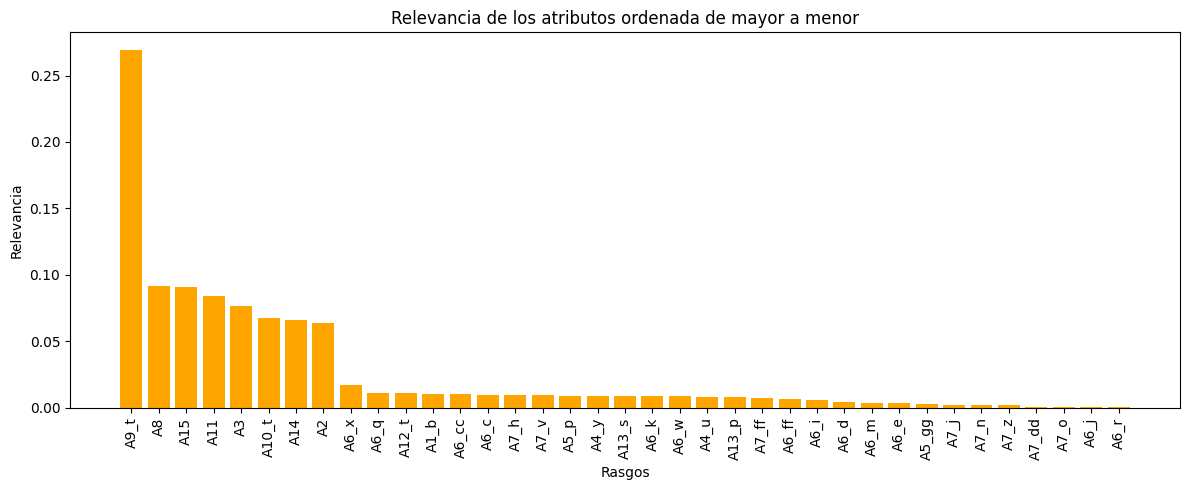

El rasgo más relevante es: A9_t


In [74]:
from sklearn.ensemble import RandomForestClassifier

# Entrenar Bosque Aleatorio (no requiere datos escalados)
bosque = RandomForestClassifier(n_estimators=200, random_state=10)
bosque.fit(X_ent, y_ent)

# Calcular relevancia
relevancias = bosque.feature_importances_
indices = np.argsort(relevancias)[::-1] # Ordenar de mayor a menor
nombres_rasgos = X.columns[indices]

# Dibujar la gráfica
plt.figure(figsize=(12, 5))
plt.bar(range(X.shape[1]), relevancias[indices], align='center', color='orange')
plt.xticks(range(X.shape[1]), nombres_rasgos, rotation=90)
plt.ylabel('Relevancia')
plt.xlabel('Rasgos')
plt.title('Relevancia de los atributos ordenada de mayor a menor')
plt.tight_layout()
plt.show()

print(f"El rasgo más relevante es: {nombres_rasgos[0]}")

e) Utilice todos los rasgos para calcular la exactitud en test mediante un bosque aleatorio. Calcule la exactitud en test de un bosque con el mismo número de estimadores (árboles), pero esta vez use únicamente los rasgos que tienen una significatividad superior al 0.05. ¿Existe diferencia entre ambas exactitudes? ¿a qué cree que se debe? Razone sus respuestas.

In [75]:
from sklearn.metrics import accuracy_score

# 1. Exactitud con TODOS los rasgos
acc_todos = accuracy_score(y_test, bosque.predict(X_test))

# 2. Filtrar rasgos con significatividad > 0.05
indices_sig = [i for i, rel in enumerate(bosque.feature_importances_) if rel > 0.05]
columnas_sig = X.columns[indices_sig]

# Entrenar un bosque nuevo solo con esas columnas
bosque_sig = RandomForestClassifier(n_estimators=200, random_state=10)
bosque_sig.fit(X_ent[columnas_sig], y_ent)

# 3. Exactitud con rasgos seleccionados
acc_sig = accuracy_score(y_test, bosque_sig.predict(X_test[columnas_sig]))

print(f"Exactitud usando todos los rasgos: {acc_todos:.4f}")
print(f"Exactitud usando rasgos > 0.05:    {acc_sig:.4f}")

Exactitud usando todos los rasgos: 0.8613
Exactitud usando rasgos > 0.05:    0.8382


La exactitud disminuye perp muy poco (de 0.8613 a 0.8382). Esto se debe a que el Bosque Aleatorio aprovecha la combinación de todas las variables. Al eliminar los rasgos "menos importantes" (< 0.05), le quitamos información que trabajando en conjunto con las demás, ayudaban al modelo a ser ligeramente más preciso.

### EJERCICIO AVANZADO
3) (2 ptos) Considere los ficheros PoblacionINE.xlsx y ViviendasINE.xlsx disponibles en el Campus Virtual y realice las siguientes tareas:

a) Cargue los datos de la población total desde PoblacionINE.xlsx a un DataFrame, los de población nacional a otro DataFrame, y los de población extranjera a un tercer DataFrame.

In [76]:
import pandas as pd

# Leemos el archivo Excel sin cabeceras
df_pob = pd.read_excel('data/PoblacionINE.xlsx', header=None)

# Recortamos exactamente las 52 filas de cada bloque
df_pob_total = df_pob.iloc[10:62].copy()
df_pob_nac = df_pob.iloc[63:115].copy()
df_pob_ext = df_pob.iloc[116:168].copy()

# Limpiamos cada bloque y ponemos "Provincia" como índice
for df in [df_pob_total, df_pob_nac, df_pob_ext]:
    df.columns = ['Provincia', 'Valor']
    df.set_index('Provincia', inplace=True)
    df['Valor'] = pd.to_numeric(df['Valor'])

# Renombramos las columnas según el enunciado
df_pob_total.columns = ['PoblacionTotal']
df_pob_nac.columns = ['PoblacionNacional']
df_pob_ext.columns = ['PoblacionExtranjera']

c:\Users\rodri\AppData\Local\Programs\Python\Python312\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


b) Cargue los datos de las viviendas totales desde ViviendasINE.xlsx a un DataFrame, los de viviendas principales a otro DataFrame, y los de viviendas no principales a un tercer DataFrame.

In [77]:
# Leemos el archivo de viviendas
df_viv = pd.read_excel('data/ViviendasINE.xlsx', header=None)

df_viv_totales = df_viv.iloc[8:60].copy()
df_viv_prin = df_viv.iloc[61:113].copy()
df_viv_no_prin = df_viv.iloc[114:166].copy()

# Limpiamos cada bloque y asignamos el índice
for df in [df_viv_totales, df_viv_prin, df_viv_no_prin]:
    df.columns = ['Provincia', 'Valor']
    df.set_index('Provincia', inplace=True)
    df['Valor'] = pd.to_numeric(df['Valor'])

# Renombramos las columnas
df_viv_totales.columns = ['ViviendasTotales']
df_viv_prin.columns = ['ViviendasPrincipales']
df_viv_no_prin.columns = ['ViviendasNoPrincipales']

c:\Users\rodri\AppData\Local\Programs\Python\Python312\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


c) Combine con la función concat de Pandas los seis DataFrames en un solo DataFrame que tenga exactamente siete columnas: Provincia (que es el índice), PoblacionTotal, PoblacionNacional, PoblacionExtranjera, ViviendasTotales, ViviendasPrincipales y ViviendasNoPrincipales. Dicho DataFrame debe tener 52 filas, una por provincia.

In [78]:
# Unimos los 6 dataframes usando concat (se alinean automáticamente por la Provincia)
df_final = pd.concat([
    df_pob_total, 
    df_pob_nac, 
    df_pob_ext, 
    df_viv_totales, 
    df_viv_prin, 
    df_viv_no_prin
], axis=1)

# Aseguramos el nombre del índice
df_final.index.name = 'Provincia'

# Comprobación de que tenemos 52 filas y 6 columnas
print(f"Dimensiones del DataFrame: {df_final.shape}")
df_final.head()

Dimensiones del DataFrame: (52, 6)


,PoblacionTotal,PoblacionNacional,PoblacionExtranjera,ViviendasTotales,ViviendasPrincipales,ViviendasNoPrincipales
Provincia,,,,,,
04 Almería,730430,575979,154451,434546,275726,158820
11 Cádiz,1249873,1197787,52086,648306,468478,179828
14 Córdoba,777622,755364,22258,414088,299409,114679
18 Granada,925046,856272,68774,573717,368011,205706
21 Huelva,527254,478386,48868,320916,201365,119551


### EJERCICIO EXPERTO
4) (2 ptos) Considere los ficheros DatosHistoricos_Eurostoxx50.csv, DatosHistoricos_SP500.csv y DatosHistoricos_EURUSD.csv disponibles en el Campus Virtual y realice las siguientes tareas:

a) Cargue los datos del índice bursátil SP500 desde DatosHistoricos_SP500.csv a un DataFrame, los del índice EuroStoxx50 desde DatosHistoricos_Eurostoxx50.csv a otro DataFrame, y los del tipo de cambio euro/dólar desde DatosHistoricos_EURUSD.csv a un tercer DataFrame. Tenga en cuenta que el campo Date de dichos ficheros es una fecha.

In [79]:
import pandas as pd

# Cargamos los archivos
df_sp500 = pd.read_csv('data/DatosHistoricos_SP500.csv', parse_dates=['Date'])
df_euro = pd.read_csv('data/DatosHistoricos_Eurostoxx50.csv', parse_dates=['Date'])
df_eurusd = pd.read_csv('data/DatosHistoricos_EURUSD.csv', parse_dates=['Date'])

# Mostramos información básica
print("SP500:", df_sp500.shape)
print("EuroStoxx50:", df_euro.shape)
print("EURUSD:", df_eurusd.shape)

SP500: (2538, 6)
EuroStoxx50: (4093, 7)
EURUSD: (1282, 6)


b) Cree un DataFrame que contenga los datos de cierre (Close) de las tres series (SP500, EuroStoxx50 y euro/dólar), para los días que haya datos de las tres series. Debe usar la función merge de Pandas. El DataFrame debe tener exactamente cuatro columnas: Date, CloseSP500, CloseEuroStoxx50 y CloseEURUSD.

In [80]:
# 1. Filtramos las columnas de fecha y cierre
df_sp500_close = df_sp500[['Date', 'Close/Last']].copy()
df_euro_close = df_euro[['Date', 'Close']].copy()
df_eurusd_close = df_eurusd[['Date', 'Close/Last']].copy()

# 2. Renombramos las columnas para que se llamen exactamente como pide el enunciado
df_sp500_close = df_sp500_close.rename(columns={'Close/Last': 'CloseSP500'})
df_euro_close = df_euro_close.rename(columns={'Close': 'CloseEuroStoxx50'})
df_eurusd_close = df_eurusd_close.rename(columns={'Close/Last': 'CloseEURUSD'})

# 3. Unimos los DataFrames en cascada usando la columna 'Date' como nexo
df_fusion = pd.merge(df_sp500_close, df_euro_close, on='Date')
df_final_b = pd.merge(df_fusion, df_eurusd_close, on='Date')

print(f"Dimensiones tras cruzar los datos: {df_final_b.shape}")
df_final_b.head()

Dimensiones tras cruzar los datos: (1018, 4)


,Date,CloseSP500,CloseEuroStoxx50,CloseEURUSD
0,2023-07-06,4411.59,4223.089844,1.0888
1,2023-07-05,4446.82,4350.709961,1.0842
2,2023-07-03,4455.59,4398.149902,1.0907
3,2023-06-30,4450.38,4399.089844,1.0912
4,2023-06-29,4396.44,4354.689941,1.0875


c) Añada al DataFrame obtenido en el apartado anterior una quinta columna llamada CloseEuroStoxx50USD que sea el valor del índice EuroStoxx50 en dólares, es decir, la columna CloseEuroStoxx50 multiplicada por la columna CloseEURUSD.

In [81]:
# Multiplicamos el valor de cierre del índice europeo por el tipo de cambio 
df_final_b['CloseEuroStoxx50USD'] = df_final_b['CloseEuroStoxx50'] * df_final_b['CloseEURUSD']

# Mostramos las primeras filas para verificar que se ha creado la quinta columna
df_final_b.head()

,Date,CloseSP500,CloseEuroStoxx50,CloseEURUSD,CloseEuroStoxx50USD
0,2023-07-06,4411.59,4223.089844,1.0888,4598.100222
1,2023-07-05,4446.82,4350.709961,1.0842,4717.039740
2,2023-07-03,4455.59,4398.149902,1.0907,4797.062098
3,2023-06-30,4450.38,4399.089844,1.0912,4800.286838
4,2023-06-29,4396.44,4354.689941,1.0875,4735.725311
